# 04 · Stability

Checks whether the partitions would come out the same with a slightly different sample.

`SampleDistClustering` is used here without subsampling (`frac_sample_size = 1`), so changing the random seed
gives the same partition every time. Instead, the patients are resampled:

1. Draw 216 patients with replacement (a bootstrap sample; the seed is the refit number).
2. Refit the configuration on that sample: distance, robust covariance, block variabilities and medoids
   (or centroids for k-means).
3. Assign all 216 original patients to the nearest medoid or centroid.
4. Repeat 30 times and compute the Adjusted Rand Index (ARI) between every pair of the 30 partitions (435 pairs).
   ARI = 1 means identical partitions, 0 means no more agreement than chance.

The RelMS configurations (I1, M1) are left out because the library assigns new patients with the G-Gower point
distance, so RelMS would not be refitted exactly.

In [1]:
import json, itertools

%run -i ../src/setup.ipynb

from sklearn.metrics import adjusted_rand_score

CMP = cfg.RESULTS_DIR / "02_compare_configurations"
OUT = cfg.RESULTS_DIR / "04_stability"
OUT.mkdir(parents=True, exist_ok=True)

selection = json.loads((CMP / "selection.json").read_text())
SEL, K = selection["selected"], selection["k"]
full_labels = pd.read_csv(CMP / "labels.csv")
df = load_analysis_data()

CONFIGS = [SEL] + [n for n in ["C1", "C1-b", "C2", "I2", "I2-b", "M2", "M3"] if n != SEL]
print("selected:", SEL, "| k =", K, "| refits =", cfg.N_STABILITY_REFITS)

selected: C1-b | k = 4 | refits = 30


## 1. Bootstrap refits

In [2]:
partitions = {}
for name in CONFIGS:
    metric = selection["m3_metric"] if name == "M3" else None
    partitions[name] = bootstrap_partitions(name, K, df, metric=metric)
    print(f"{name:5s} done")
np.savez_compressed(OUT / "bootstrap_partitions.npz", **{n.replace("-", "_"): p for n, p in partitions.items()})

C1-b  done


C1    done


C2    done


I2    done


I2-b  done


M2    done


M3    done


## 2. Agreement between refits

- Pairwise ARI: between every pair of the 30 refits.
- ARI with the full-data partition: between each refit and the partition of notebook 02.

In [3]:
pairwise, rows = {}, []
for name, P in partitions.items():
    pw = np.array([adjusted_rand_score(P[i], P[j]) for i, j in itertools.combinations(range(len(P)), 2)])
    vs_full = np.array([adjusted_rand_score(full_labels[name], p) for p in P])
    pairwise[name] = pw
    rows.append({"configuration": name, "pairs": len(pw), "mean": pw.mean(), "SD": pw.std(ddof=1),
                 "median": np.median(pw), "min": pw.min(), "max": pw.max(),
                 "mean ARI vs full-data partition": vs_full.mean()})
summary = pd.DataFrame(rows).set_index("configuration").round(3)
summary.to_csv(OUT / "stability_summary.csv")
summary

,pairs,mean,SD,median,min,max,mean ARI vs full-data partition
configuration,,,,,,,
C1-b,435,0.749,0.109,0.744,0.451,0.964,0.816
C1,435,0.336,0.129,0.314,0.115,0.868,0.366
C2,435,0.371,0.117,0.359,0.127,0.930,0.393
I2,435,0.155,0.096,0.146,-0.045,0.681,0.204
I2-b,435,0.489,0.131,0.479,0.150,0.880,0.559
M2,435,0.202,0.095,0.185,0.042,0.574,0.264
M3,435,0.197,0.091,0.180,0.050,0.618,0.239


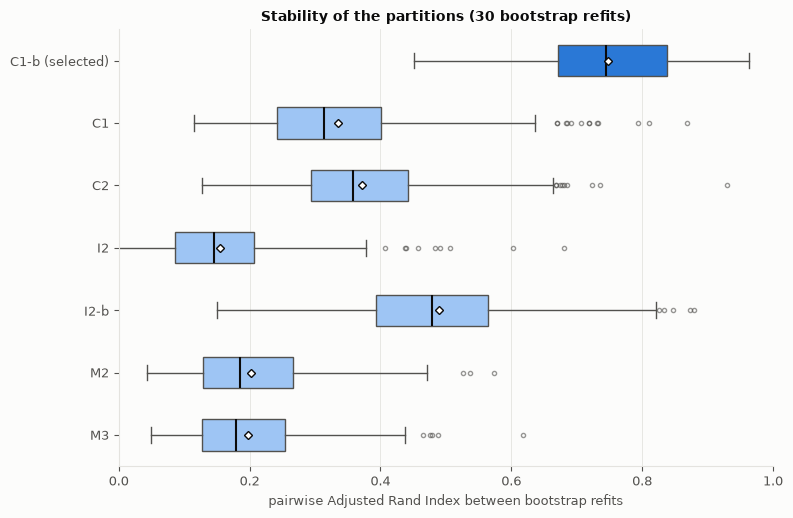

In [4]:
fig = stability_boxplot(pairwise, highlight=SEL)
fig.savefig(OUT / "stability_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Cross-check without duplicated patients

A bootstrap sample repeats some patients and leaves out others (about 37%). To check that this does not
change the ranking, the procedure is repeated with 30 subsamples of 80% of the patients drawn without
replacement (seeds 0–29), again assigning all 216 patients afterwards.

In [5]:
from sklearn.cluster import KMeans

def subsample_partitions(name, frac=0.8, n_refits=cfg.N_STABILITY_REFITS):
    c = cfg.CONFIGS[name]
    out = []
    for r in range(n_refits):
        idx = np.random.default_rng(r).choice(len(df), int(frac * len(df)), replace=False)
        if c["algorithm"] == "kmeans":
            X = build_kmeans_matrix(df, c)["X"]
            out.append(KMeans(K, random_state=cfg.RANDOM_STATE, n_init=cfg.KMEANS_N_INIT).fit(X[idx]).predict(X))
            continue
        d = build_design(df, c)
        m = ExactRelMSSampleDistClustering(
            make_pam(K), metric=selection["m3_metric"] if name == "M3" else c["metric"],
            frac_sample_size=cfg.FRAC_SAMPLE_SIZE, random_state=cfg.RANDOM_STATE,
            p1=d["p1"], p2=d["p2"], p3=d["p3"], d1=d["d1"], d2=d["d2"], d3=d["d3"],
            robust_method=cfg.ROBUST_METHOD, alpha=cfg.ALPHA).fit(d["X"][idx])
        out.append(np.asarray(m.predict(d["X"])).astype(int))
    return out

rows = []
for name in CONFIGS:
    P = subsample_partitions(name)
    pw = np.array([adjusted_rand_score(P[i], P[j]) for i, j in itertools.combinations(range(len(P)), 2)])
    rows.append({"configuration": name, "mean": pw.mean(), "median": np.median(pw), "min": pw.min()})
sub = pd.DataFrame(rows).set_index("configuration").round(3)
sub.to_csv(OUT / "stability_subsampling80.csv")
sub

,mean,median,min
configuration,,,
C1-b,0.845,0.842,0.624
C1,0.433,0.376,0.145
C2,0.432,0.375,0.166
I2,0.408,0.332,0.087
I2-b,0.589,0.555,0.248
M2,0.514,0.511,0.110
M3,0.453,0.443,0.087


## 4. Interpretation

- The selected configuration is stable: C1-b's refits agree with each other at a mean pairwise ARI of 0.75
  (median 0.74) and with the full-data partition at 0.82; with 80% subsamples the agreement is 0.85.
- The k-medoids partitions are much less reproducible: C1 0.34, C2 0.37, M2 0.20, M3 0.20 and I2 0.16 with the
  bootstrap, and 0.41 to 0.51 with 80% subsamples. With both procedures C1-b is far above all the others.
  With the patients forming a continuum (low silhouettes, notebook 01), many different sets of four medoids fit almost equally well.
- I2-b (k-means on the images) is more stable than the k-medoids image configurations (0.49 with the bootstrap,
  0.59 with subsamples), but its groups hardly differ on any clinical variable (PSI 0.12, the lowest of all): the
  images contain a reproducible structure, but not a clinically meaningful one.
- Together with the PSI, this supports C1-b: it separates the interpretation variables most clearly and its
  partition is reproducible. The partitions of the k-medoids configurations are better seen as one of several
  similar solutions.